In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('data/creditcard.csv')
print(f"Dataset shape: {df.shape}")
print(f"Fraud cases: {df['Class'].sum()} ({df['Class'].mean()*100:.4f}%)")

Dataset shape: (284807, 31)
Fraud cases: 492 (0.1727%)


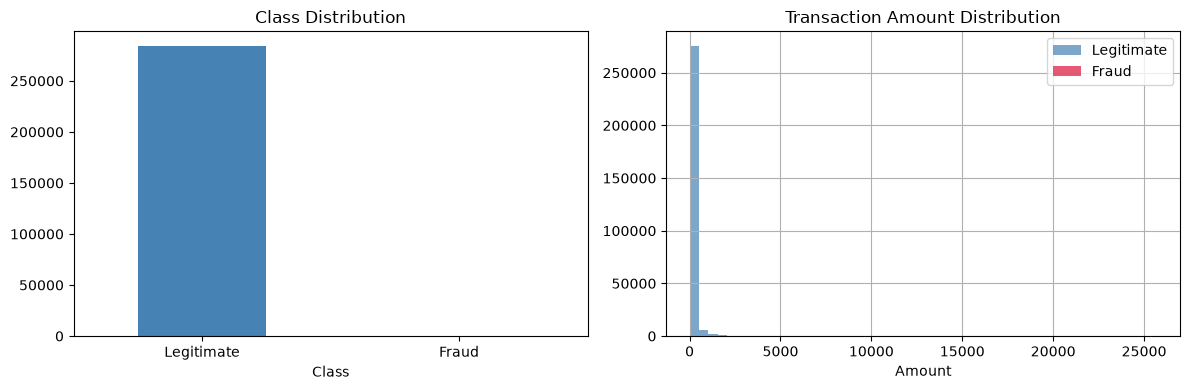

Missing values: 0


In [2]:
# Class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Class'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'crimson'])
axes[0].set_title('Class Distribution')
axes[0].set_xticklabels(['Legitimate', 'Fraud'], rotation=0)

# Transaction amount by class
df[df['Class'] == 0]['Amount'].hist(ax=axes[1], bins=50, alpha=0.7, label='Legitimate', color='steelblue')
df[df['Class'] == 1]['Amount'].hist(ax=axes[1], bins=50, alpha=0.7, label='Fraud', color='crimson')
axes[1].set_title('Transaction Amount Distribution')
axes[1].set_xlabel('Amount')
axes[1].legend()
plt.tight_layout()
plt.show()

# Check for missing values
print(f"Missing values: {df.isnull().sum().sum()}")

In [3]:
# Scale Amount and Time using RobustScaler (robust to outliers)
scaler = RobustScaler()

df['scaled_amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1, 1))

# Drop the original columns
df.drop(['Time', 'Amount'], axis=1, inplace=True)

# Move scaled columns to front for readability
scaled_amount = df.pop('scaled_amount')
scaled_time = df.pop('scaled_time')
df.insert(0, 'scaled_amount', scaled_amount)
df.insert(1, 'scaled_time', scaled_time)

print("Preprocessing complete. Shape:", df.shape)
print(df.head(3))

Preprocessing complete. Shape: (284807, 31)
   scaled_amount  scaled_time        V1        V2        V3        V4  \
0       1.783274    -0.994983 -1.359807 -0.072781  2.536347  1.378155   
1      -0.269825    -0.994983  1.191857  0.266151  0.166480  0.448154   
2       4.983721    -0.994972 -1.358354 -1.340163  1.773209  0.379780   

         V5        V6        V7        V8  ...       V20       V21       V22  \
0 -0.338321  0.462388  0.239599  0.098698  ...  0.251412 -0.018307  0.277838   
1  0.060018 -0.082361 -0.078803  0.085102  ... -0.069083 -0.225775 -0.638672   
2 -0.503198  1.800499  0.791461  0.247676  ...  0.524980  0.247998  0.771679   

        V23       V24       V25       V26       V27       V28  Class  
0 -0.110474  0.066928  0.128539 -0.189115  0.133558 -0.021053      0  
1  0.101288 -0.339846  0.167170  0.125895 -0.008983  0.014724      0  
2  0.909412 -0.689281 -0.327642 -0.139097 -0.055353 -0.059752      0  

[3 rows x 31 columns]


In [4]:
# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Stratified split to preserve fraud ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples, {y_train.sum()} frauds")
print(f"Test set: {X_test.shape[0]} samples, {y_test.sum()} frauds")

Training set: 227845 samples, 394 frauds
Test set: 56962 samples, 98 frauds


In [5]:
# Apply SMOTE to training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE: {y_train.value_counts().to_dict()}")
print(f"After SMOTE: {y_train_resampled.value_counts().to_dict()}")

Before SMOTE: {0: 227451, 1: 394}
After SMOTE: {0: 227451, 1: 227451}


In [6]:
# Train Random Forest on SMOTE-balanced data
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_resampled, y_train_resampled)
print("Random Forest trained successfully.")

Random Forest trained successfully.


CLASSIFICATION REPORT (Fraud Class Focus)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.40      0.87      0.55        98

    accuracy                           1.00     56962
   macro avg       0.70      0.93      0.77     56962
weighted avg       1.00      1.00      1.00     56962



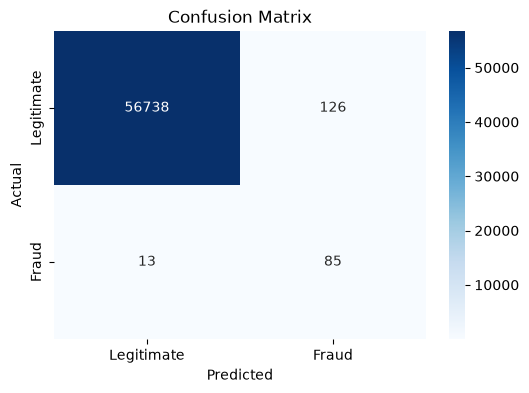

Precision-Recall AUC: 0.8126


In [7]:
# Predict on the REAL, unseen test set
y_pred = rf_model.predict(X_test)
y_probs = rf_model.predict_proba(X_test)[:, 1]

# Classification report
print("=" * 50)
print("CLASSIFICATION REPORT (Fraud Class Focus)")
print("=" * 50)
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Fraud'],
            yticklabels=['Legitimate', 'Fraud'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Precision-Recall AUC (more informative than ROC-AUC for imbalance)
precision, recall, _ = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)
print(f"Precision-Recall AUC: {pr_auc:.4f}")

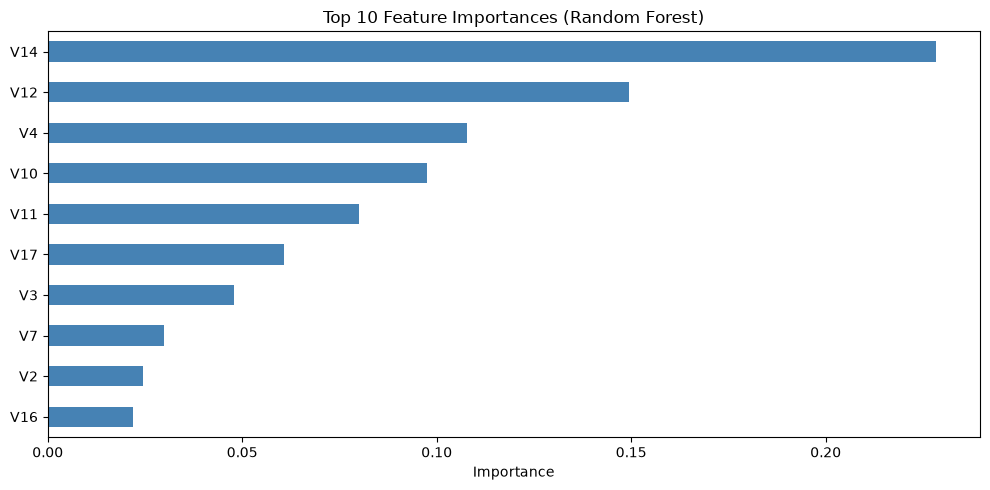

In [9]:
# Feature importance from Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_features.plot(kind='barh', color='steelblue')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()